# 실험 로그와 자동 실행

**이 노트북에서 할 일**

1. 개발 분할 15문항의 세 지표를 설정·날짜·입력 지문과 함께 기록 한 줄로 만들어 파일에 남깁니다.
2. 실습 폴더 도구 `evaluate.py`를 다른 프로그램으로 실행해 앞 챕터 기록의 보고서를 만듭니다.
3. 노트북이 직접 계산한 값과 도구가 적은 값이 같은지 한 줄씩 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열여섯 번입니다. 색인 한 벌에 한 번, 질문 검색에 열다섯 번입니다.

실습 폴더 도구는 기록 파일만 읽으므로 요청을 보내지 않습니다.
답을 쓰는 모델도 이 절에서 부르지 않습니다.

보낼 조각 수는 색인이 59190개 어림이고 질문은 한 번에 스무 개 안팎입니다.
예상 비용은 열여섯 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)의 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 네 갈래이고 모두 실습 묶음에 들어 있습니다.

- 말뭉치 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건과 `labs/data/rag-corpus/manifest.json`
- 평가셋 `labs/part3/ch11-evaluation/data/evaluation-queries.jsonl`
- Ch 9 06절 기록 `labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl`
- Ch 10 08절 기록 `labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl`

**이 절은 파일을 씁니다** — 01~05절과 달리 실습 폴더 `runs/` 폴더에 파일 세 개를 남깁니다.
이름 끝에 오늘 날짜가 붙어 같은 날 다시 실행하면 같은 파일을 덮어씁니다.
앞 챕터가 남긴 기록 파일은 읽기만 하고 고치지 않습니다.

**강의와 실습 범위** — 강의 시간에는 2·6~12절을 설명합니다.
기록에 담을 칸, 입력 지문, 기록 한 줄 만들기, 파일로 남기기, 도구 자동 실행, 값 대조입니다.
3절 지표 함수는 도구 파일에서 가져오고, 4·5절 색인 만들기는 02~05절과 같은 코드라 실행만 하고 넘어갑니다.

**기준 버전** — 고정한 패키지는 다섯 개입니다.

- 쪽 읽기: pypdf 6.1.1
- 색인과 임베딩: langchain-core 1.6.2 · langchain-openai 1.6.0
- 코사인 유사도 계산: numpy 2.5.3
- 키 읽기: python-dotenv 1.2.3

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch11-evaluation`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

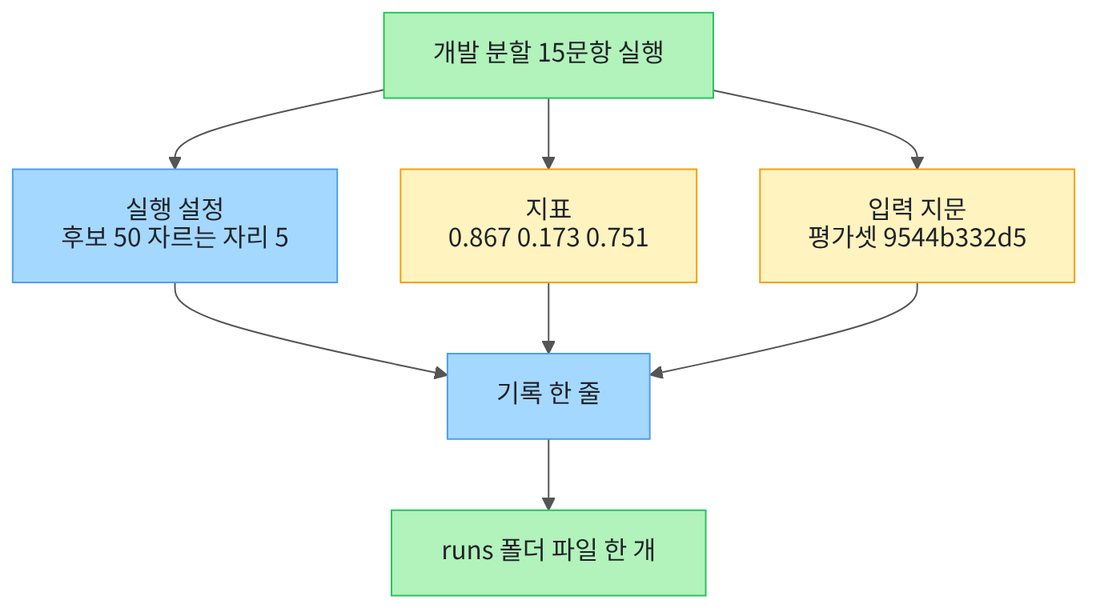

맨 위 초록 상자가 이 절이 남길 실행입니다. 02~05절과 같은 개발 분할 15문항입니다.
그 아래 세 상자가 기록에 담을 세 갈래입니다. 실행 설정과 지표와 입력 지문입니다.

세 갈래가 가운데 파란 상자에서 기록 한 줄로 모입니다.
맨 아래 초록 상자가 그 한 줄을 담은 파일입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
02~05절에서 쓴 다섯 개와 같습니다. 이 절도 같은 색인을 다시 만들기 때문입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.1.1" "langchain-core==1.6.2" "langchain-openai==1.6.0" "numpy==2.5.3" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("numpy:", version("numpy"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.1.1
langchain-core: 1.6.2


langchain-openai: 1.6.0
numpy: 2.5.3
python-dotenv: 1.2.3


**결과 읽기** — 출력 다섯 줄 가운데 첫 줄은 `pypdf: 6.1.1`입니다.
둘째 줄 `langchain-core: 1.6.2`와 셋째 줄 `langchain-openai: 1.6.0`도 보세요.
넷째 줄 `numpy: 2.5.3`은 색인이 코사인 유사도를 계산할 때 쓰는 패키지입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다. 05절 목록에 네 개가 늘었습니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 01~05절 함수 여섯 개와 Ch 9 02절 `load_pdf_pages()`를 가져옵니다.
01절 `unique_doc_ids()`, 02절 `recall_at()`·`mean_score()`, 03절 `precision_at()`, 04절 `ndcg_at()`, 05절 `search()`입니다.

함수 `search()`는 05절 판과 인자 모양이 다릅니다.
05절 판이 노트북에서 바로 읽던 벡터스토어와 후보 개수를 첫째와 넷째 인자로 받습니다.

In [2]:
# 지문 만들기·기록 읽고 쓰기·도구 실행·날짜·색인에 쓸 이름을 불러옵니다
import hashlib
import json
import subprocess
import sys
import time

from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
# 01~05절과 Ch 9 02절 함수 일곱 개를 도구 파일에서 가져옵니다
from rag_tools import load_pdf_pages, mean_score, ndcg_at, precision_at
from rag_tools import recall_at, search, unique_doc_ids

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.
모듈 `hashlib`은 01절에서 평가셋 파일 지문을 만들 때 쓴 모듈입니다.

새로 불러온 것은 `subprocess`와 `sys`와 `time`입니다.
앞의 두 모듈은 Ch 2 08절과 Ch 3 05절에서 다른 프로그램을 실행할 때 썼습니다.
모듈 `time`은 Ch 6 06절에서 요청 기록에 시각을 적을 때 썼습니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.
이 셀은 모듈 `os`도 함께 불러옵니다. 뒤에서 파일과 폴더를 다룰 때 씁니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~05절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: ../../../..


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 고른 경로에 파일 이름을 이어 붙여 네 갈래 경로를 만듭니다.

In [5]:
# 이 절에서 읽을 파일 네 갈래의 경로를 만듭니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
dataset_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
ch09_log_path = root_path + "/labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_log_path = root_path + "/labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
print("평가셋 파일이 있는가:", os.path.exists(dataset_path))
print("말뭉치 목록이 있는가:", os.path.exists(manifest_path))
print("Ch 9 기록이 있는가:", os.path.exists(ch09_log_path))
print("Ch 10 기록이 있는가:", os.path.exists(ch10_log_path))

평가셋 파일이 있는가: True
말뭉치 목록이 있는가: True
Ch 9 기록이 있는가: True
Ch 10 기록이 있는가: True


**결과 읽기** — 네 줄 모두 `True`입니다. 02~05절이 읽은 네 갈래와 같습니다.

## 2. 이 절이 쓸 값 정하기

05절까지는 값을 화면에 출력하기만 했습니다. 커널을 끄면 그 값은 사라집니다.
며칠 뒤에 다시 보려면 어떤 설정이 만든 값인지 파일에 적어 두어야 합니다.

먼저 평가셋 30줄을 읽고 개발 분할 15문항만 남깁니다. 02~05절과 같은 코드입니다.

In [6]:
# 평가셋 30줄을 읽고 설정을 고를 때 쓰는 개발 분할만 남깁니다(05절 2절과 같은 코드)
with open(dataset_path, encoding="utf-8") as dataset_file:
    dataset_lines = dataset_file.read().splitlines()

queries = []
for line in dataset_lines:
    queries.append(json.loads(line))

dev_queries = []
for query in queries:
    if query["split"] == "dev":
        dev_queries.append(query)
print("평가셋 줄 수:", len(queries))
print("개발 분할 질문 수:", len(dev_queries))
print("첫 질문 번호:", dev_queries[0]["qid"])

평가셋 줄 수: 30
개발 분할 질문 수: 15
첫 질문 번호: Q001


**결과 읽기** — 출력 줄은 `평가셋 줄 수: 30`과 `개발 분할 질문 수: 15`입니다.
셋째 줄 `첫 질문 번호: Q001`은 02~05절에서 후보 목록을 본 그 질문입니다.

다음 셀은 이 절에서 쓸 수 세 개를 정합니다.
앞의 둘은 02~05절과 같은 값이고 셋째가 이 절에서 새로 정하는 값입니다.
보고서 자리 수는 계산에 쓰는 수가 아니라 보고서에 몇 줄까지 적어 둘지를 정하는 수입니다.

In [7]:
# 후보 개수와 자르는 자리는 02~05절과 같은 값으로 두고 보고서 자리 수를 새로 정합니다
candidate_count = 50
cutoff_narrow = 5
report_k = 5
print("후보 개수:", candidate_count)
print("자르는 자리:", cutoff_narrow)
print("보고서 자리 수:", report_k)

후보 개수: 50
자르는 자리: 5
보고서 자리 수: 5


**결과 읽기** — 세 줄은 `후보 개수: 50`과 `자르는 자리: 5`와 `보고서 자리 수: 5`입니다.
앞의 두 값을 바꾸면 02~05절과 비교가 끊깁니다. 셋째 값은 12절에서 한 번 바꿔 봅니다.

## 3. 앞 절 지표 함수

01~04절에서 만든 지표 함수는 준비 셀에서 도구 파일로부터 가져왔습니다. 이 절은 지표 공식을 바꾸지 않습니다.
세 지표 함수 `recall_at()`·`precision_at()`·`ndcg_at()`은 모두 `doc_ids`와 `gold_doc_ids`와 `cutoff`를 받습니다.
인자 모양이 같아 한 반복문에서 세 값을 함께 낼 수 있습니다.

## 4. 기준선 색인 만들기

02~05절과 같은 다섯 셀입니다. 같은 색인을 다시 만들어야 이 절 값이 앞 절 값과 이어집니다.
먼저 말뭉치 목록에서 스캔 변형을 뺍니다.

In [8]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다(02절 5절과 같은 코드)
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())

digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))

목록의 전체 행 수: 21
디지털 PDF 수: 18


**결과 읽기** — 출력 줄은 `목록의 전체 행 수: 21`과 `디지털 PDF 수: 18`입니다.
02~05절에서 본 값과 같습니다.

다음 셀은 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.
읽기는 준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`가 맡습니다.
메타데이터 칸 이름은 Ch 10 01절에서 정한 `doc_id`·`page`·`source`입니다.

In [9]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다(02절 5절과 같은 코드)
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))

읽은 문서 수: 18
읽은 쪽 수: 93


**결과 읽기** — 출력 줄은 `읽은 문서 수: 18`과 `읽은 쪽 수: 93`입니다.
02~05절과 같은 값입니다.

다음 셀은 글자 층이 빈 쪽을 빼고 색인 재료를 고릅니다.

In [10]:
# 글자 층이 빈 쪽을 빼고 색인 재료를 고른 뒤 글이 있는 문서 수를 셉니다(02절 5절과 같은 코드)
index_pages = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) > 0:
        index_pages.append(page_document)
        if page_document.metadata["doc_id"] not in text_doc_ids:
            text_doc_ids.append(page_document.metadata["doc_id"])
print("색인에 넣을 쪽 수:", len(index_pages))
print("글이 있는 문서 수:", len(text_doc_ids))

색인에 넣을 쪽 수: 90
글이 있는 문서 수: 17


**결과 읽기** — 출력 줄은 `색인에 넣을 쪽 수: 90`과 `글이 있는 문서 수: 17`입니다.
읽은 쪽 93개에서 세 쪽이 빠졌습니다.

빠진 세 쪽은 Ch 10 08절에서 글자 층이 비는 것을 확인한 `H05`의 쪽입니다.

다음 셀은 임베딩 모델을 준비하고 쪽 90개로 색인 한 벌을 만듭니다.
여기서 임베딩 요청 한 번이 나갑니다.

In [11]:
# 임베딩 모델을 준비하고 쪽 Document 90개로 색인 한 벌을 만듭니다(02절 5절과 같은 코드)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
store.add_documents(index_pages)
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("색인에 들어간 항목 수:", len(store.store))

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
색인에 들어간 항목 수: 90


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
둘째 줄 `차원 수를 주었는가: False`는 Ch 10 07절에서 정한 기본 설정으로 벡터를 만들었다는 뜻입니다.
셋째 줄 `색인에 들어간 항목 수: 90`은 앞 셀에서 고른 쪽 수와 같습니다.
이 노트북의 출력은 2026-09-21에 이 임베딩 모델로 실행한 결과입니다.

## 5. 검색해서 세 지표 내기

검색은 준비 셀에서 가져온 05절 함수 `search()`로 합니다.
셋째 인자 볼 자리 수와 넷째 인자 후보 개수를 모두 50으로 주어 고유 문서 목록을 자르지 않고 받습니다.

다음 셀은 개발 분할 15문항을 차례로 검색합니다. 질문 하나에 임베딩 요청 한 번이 나갑니다.
반복문 안에서는 목록만 모으고 끝난 뒤에 한꺼번에 출력합니다.

In [12]:
# 개발 분할 15문항을 차례로 검색해 질문마다 고유 문서 목록을 모읍니다
unique_by_qid = {}
for query in dev_queries:
    query_hits = search(store, query["question"], candidate_count, candidate_count)
    unique_by_qid[query["qid"]] = unique_doc_ids(query_hits)
print("검색한 질문 수:", len(unique_by_qid))
print("질문 Q001의 앞 5자리:", unique_by_qid["Q001"][:cutoff_narrow])

검색한 질문 수: 15
질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']


**결과 읽기** — 첫 줄은 `검색한 질문 수: 15`입니다.
둘째 줄은 `질문 Q001의 앞 5자리: ['E01', 'M04', 'H03', 'M05', 'E04']`입니다.
02~05절 노트북에서 본 목록과 같습니다.

받은 개수는 이 절에서도 출력하지 않습니다.
후보 50개의 뒤쪽 순서가 실행마다 달라져 고유 문서 수가 한두 개 움직이기 때문입니다.

다음 셀은 질문마다 세 지표를 내고 세 목록에 모읍니다.
실행 전에 예상합니다. 05절과 같은 색인이므로 평균 세 값이 05절과 같을 것입니다.

In [13]:
# 개발 분할 15문항의 세 지표를 각각 목록에 모읍니다
recall_scores = []
precision_scores = []
ndcg_scores = []
for query in dev_queries:
    doc_ids = unique_by_qid[query["qid"]]
    gold_ids = query["gold_doc_ids"]
    recall_scores.append(recall_at(doc_ids, gold_ids, cutoff_narrow))
    precision_scores.append(precision_at(doc_ids, gold_ids, cutoff_narrow))
    ndcg_scores.append(ndcg_at(doc_ids, gold_ids, cutoff_narrow))
print("모은 재현율 수:", len(recall_scores))
print("모은 nDCG 수:", len(ndcg_scores))

모은 재현율 수: 15
모은 nDCG 수: 15


**결과 읽기** — 출력 줄은 `모은 재현율 수: 15`와 `모은 nDCG 수: 15`입니다.
질문마다 값 하나씩이라 목록 길이가 질문 수와 같습니다.

다음 셀은 세 목록을 각각 질문 평균으로 줄입니다.

In [14]:
# 세 목록을 각각 같은 무게로 평균해 이 실행의 지표 세 값을 냅니다
recall_mean = mean_score(recall_scores)
precision_mean = mean_score(precision_scores)
ndcg_mean = mean_score(ndcg_scores)
print("질문 평균 재현율:", recall_mean)
print("질문 평균 정밀도:", precision_mean)
print("질문 평균 nDCG:", ndcg_mean)

질문 평균 재현율: 0.867
질문 평균 정밀도: 0.173
질문 평균 nDCG: 0.751


**결과 읽기** — 세 줄은 `질문 평균 재현율: 0.867`과 `질문 평균 정밀도: 0.173`과
`질문 평균 nDCG: 0.751`입니다. 05절 6절에서 낸 세 값과 같습니다. 예상한 대로입니다.

이 세 값이 이 절에서 기록에 담을 지표입니다.

## 6. 입력 파일 지문 만들기

지표만 적어 두면 며칠 뒤에 같은 자료로 잰 값인지 알 수 없습니다.
그래서 읽은 파일의 지문을 함께 적습니다. 지문은 Ch 7 08절에서 정한 말이고
01절에서 평가셋 파일에 한 번 만들어 보았습니다.

다음 셀은 평가셋 파일과 말뭉치 목록 파일의 지문을 만듭니다.

In [15]:
# 읽은 파일 두 개를 바이트로 열어 지문을 만들고 앞 10자만 봅니다(01절 9절과 같은 방법)
with open(dataset_path, "rb") as dataset_bytes:
    dataset_fingerprint = hashlib.sha256(dataset_bytes.read()).hexdigest()

with open(manifest_path, "rb") as manifest_bytes:
    corpus_fingerprint = hashlib.sha256(manifest_bytes.read()).hexdigest()
print("평가셋 지문 앞 10자:", dataset_fingerprint[:10])
print("말뭉치 지문 앞 10자:", corpus_fingerprint[:10])

평가셋 지문 앞 10자: 9544b332d5
말뭉치 지문 앞 10자: 27541f4121


**결과 읽기** — 출력 줄은 `평가셋 지문 앞 10자: 9544b332d5`와
`말뭉치 지문 앞 10자: 27541f4121`입니다.
첫 줄은 01절 9절에서 본 값과 같습니다. 평가셋 파일이 그대로라는 뜻입니다.

다음 셀은 Ch 10 08절 기록에 적힌 지문과 방금 만든 지문을 견줍니다.
그 기록도 같은 자리에 지문을 적어 두었습니다.

In [16]:
# Ch 10 기록 첫 줄에 적힌 두 지문과 방금 만든 지문이 같은지 봅니다
with open(ch10_log_path, encoding="utf-8") as ch10_file:
    ch10_lines = ch10_file.read().splitlines()

first_record = json.loads(ch10_lines[0])
logged_inputs = first_record["config"]["inputs"]
print("Ch 10 기록 줄 수:", len(ch10_lines))
print("기록에 적힌 말뭉치 지문 앞 10자:", logged_inputs["corpus_manifest_sha256"][:10])
print("말뭉치 지문이 같은가:", logged_inputs["corpus_manifest_sha256"] == corpus_fingerprint)
print("평가셋 지문이 같은가:", logged_inputs["evaluation_dataset_sha256"] == dataset_fingerprint)

Ch 10 기록 줄 수: 6
기록에 적힌 말뭉치 지문 앞 10자: 27541f4121
말뭉치 지문이 같은가: True
평가셋 지문이 같은가: True


**결과 읽기** — 첫 줄은 `Ch 10 기록 줄 수: 6`입니다.
둘째 줄 `기록에 적힌 말뭉치 지문 앞 10자: 27541f4121`은 앞 셀에서 만든 값과 같습니다.
셋째 줄과 넷째 줄은 모두 `True`입니다.

두 지문이 같으므로 Ch 10 08절과 이 절은 같은 말뭉치와 같은 평가셋을 읽었습니다.
지문이 달랐다면 같은 지표 이름이라도 전후로 견주기 어렵습니다.

## 7. 기록 한 줄 만들기

이제 기록에 담을 것이 모였습니다. 먼저 결과를 만든 값들을 실행 설정 한 덩어리로 모읍니다.

In [17]:
# 결과에 영향을 준 값들을 실행 설정 한 덩어리로 모읍니다
run_settings = {"검색 방법": "임베딩 유사도"}
run_settings["임베딩 모델"] = embedding_model_name
run_settings["색인 항목 수"] = len(index_pages)
run_settings["후보 개수"] = candidate_count
run_settings["자르는 자리"] = cutoff_narrow
run_settings["질문 분할"] = "dev"
print("실행 설정 칸 수:", len(run_settings))
print("실행 설정:", run_settings)

실행 설정 칸 수: 6
실행 설정: {'검색 방법': '임베딩 유사도', '임베딩 모델': 'text-embedding-3-small', '색인 항목 수': 90, '후보 개수': 50, '자르는 자리': 5, '질문 분할': 'dev'}


**결과 읽기** — 첫 줄은 `실행 설정 칸 수: 6`입니다.
둘째 줄에 여섯 칸이 모두 보입니다. 칸 `'색인 항목 수': 90`과 `'후보 개수': 50`이 그 가운데 둘입니다.

칸 이름은 한국어로 두었습니다. 이 기록은 이 노트북이 다시 읽으려고 남기는 파일입니다.
뒤에서 볼 실습 폴더 도구의 보고서는 다른 스크립트가 읽으므로 영어 칸 이름을 씁니다.

다음 셀은 실행 ID와 날짜와 지표를 더해 기록 한 줄을 만듭니다.
함수 `time.strftime()`은 Ch 6 06절에서 요청 기록에 시각을 적을 때 쓴 함수입니다.

In [18]:
# 실행 ID·날짜·설정·지문·지표를 한 딕셔너리로 모아 기록 한 줄을 만듭니다
run_day = time.strftime("%Y%m%d")
run_record = {"실행 ID": "embed-dev-" + run_day}
run_record["실행 날짜"] = time.strftime("%Y-%m-%d")
run_record["지표 규칙 이름"] = "고유 문서 기준 질문 평균 v1"
run_record["실행 설정"] = run_settings
run_record["입력 지문"] = {"평가셋": dataset_fingerprint[:10], "말뭉치 목록": corpus_fingerprint[:10]}
run_record["질문 수"] = len(dev_queries)
run_record["지표"] = {"재현율": recall_mean, "정밀도": precision_mean, "nDCG": ndcg_mean}
print("기록 한 줄:")
print(json.dumps(run_record, ensure_ascii=False, indent=2))

기록 한 줄:
{
  "실행 ID": "embed-dev-20261001",
  "실행 날짜": "2026-10-01",
  "지표 규칙 이름": "고유 문서 기준 질문 평균 v1",
  "실행 설정": {
    "검색 방법": "임베딩 유사도",
    "임베딩 모델": "text-embedding-3-small",
    "색인 항목 수": 90,
    "후보 개수": 50,
    "자르는 자리": 5,
    "질문 분할": "dev"
  },
  "입력 지문": {
    "평가셋": "9544b332d5",
    "말뭉치 목록": "27541f4121"
  },
  "질문 수": 15,
  "지표": {
    "재현율": 0.867,
    "정밀도": 0.173,
    "nDCG": 0.751
  }
}


**결과 읽기** — 라벨 줄 `기록 한 줄:` 아래에 일곱 칸이 보입니다.
칸 `"실행 ID": "embed-dev-20260921"`과 `"질문 수": 15`가 그 가운데 둘입니다.
지표 칸에는 `"재현율": 0.867`과 `"정밀도": 0.173`과 `"nDCG": 0.751`이 들어 있습니다.

지표 규칙 이름은 어떤 규칙으로 잰 값인지를 한 이름으로 적어 둔 것입니다.
이 절의 규칙은 문서 ID 중복을 먼저 빼고 질문마다 같은 무게로 평균하는 방식입니다.

## 8. 파일로 남기기

기록 한 줄은 아직 커널 안에만 있습니다. 커널을 끄면 사라집니다.
다음 셀이 그 한 줄을 파일에 적습니다.
함수 `os.makedirs()`는 Ch 7 08절에서 기록 폴더를 만들 때 쓴 함수입니다.

In [19]:
# 실습 폴더의 runs 폴더를 만들고 기록 한 줄을 날짜가 붙은 JSON 파일로 남깁니다
runs_path = root_path + "/labs/part3/ch11-evaluation/runs"
os.makedirs(runs_path, exist_ok=True)
record_name = "notebook-run-" + run_day + ".json"
record_path = runs_path + "/" + record_name
with open(record_path, "w", encoding="utf-8") as record_file:
    record_file.write(json.dumps(run_record, ensure_ascii=False, indent=2))
print("남긴 파일 이름:", record_name)
print("파일이 생겼는가:", os.path.exists(record_path))

남긴 파일 이름: notebook-run-20261001.json
파일이 생겼는가: True


**결과 읽기** — 출력 줄은 `남긴 파일 이름: notebook-run-20260921.json`과
`파일이 생겼는가: True`입니다.
이름 끝의 날짜는 실행한 날입니다. 같은 날 다시 실행하면 같은 파일을 덮어씁니다.

다음 셀은 그 파일을 다시 읽어 담은 그대로인지 봅니다.
파일을 썼다는 사실과 파일을 다시 읽었다는 사실은 서로 다른 상태입니다.

In [20]:
# 남긴 파일을 다시 읽어 칸과 값이 그대로인지 봅니다
with open(record_path, encoding="utf-8") as saved_file:
    saved_record = json.loads(saved_file.read())
print("다시 읽은 칸 이름:", saved_record.keys())
print("다시 읽은 질문 수:", saved_record["질문 수"])
print("다시 읽은 지표:", saved_record["지표"])
print("만들 때와 같은가:", saved_record == run_record)

다시 읽은 칸 이름: dict_keys(['실행 ID', '실행 날짜', '지표 규칙 이름', '실행 설정', '입력 지문', '질문 수', '지표'])
다시 읽은 질문 수: 15
다시 읽은 지표: {'재현율': 0.867, '정밀도': 0.173, 'nDCG': 0.751}
만들 때와 같은가: True


**결과 읽기** — 첫 줄에 일곱 칸 이름이 모두 보입니다.
둘째 줄은 `다시 읽은 질문 수: 15`이고 셋째 줄에 세 지표가 그대로 있습니다.
넷째 줄은 `만들 때와 같은가: True`입니다.

이제 커널을 꺼도 이 값은 남습니다.

## 9. 실습 폴더 도구를 자동으로 실행하기

기록을 손으로 만들면 절마다 칸이 조금씩 달라집니다.
그래서 실습 폴더에는 같은 계산을 늘 같은 모양으로 하는 도구 `evaluate.py`가 있습니다.
이 도구는 앞 챕터 기록 파일을 읽어 보고서 JSON을 만듭니다.

다음 셀은 도구에 넘길 상대 경로와 파일 이름을 만듭니다.
경로는 프로젝트 맨 위에서 본 모양으로 적습니다. 도구가 그 자리에서 파일을 찾기 때문입니다.

In [21]:
# 도구에 넘길 상대 경로 넷과 만들 보고서 이름을 정합니다
tool_relative = "labs/part3/ch11-evaluation/evaluate.py"
ch09_relative = "labs/part3/ch09-rag-first-run/runs/continuity-ch09-search.jsonl"
ch10_relative = "labs/part3/ch10-document-processing/runs/continuity-ch10-indexing.jsonl"
report_name = "continuity-upstream-" + run_day + ".json"
report_relative = "labs/part3/ch11-evaluation/runs/" + report_name
print("도구 파일:", tool_relative)
print("만들 보고서 이름:", report_name)

도구 파일: labs/part3/ch11-evaluation/evaluate.py
만들 보고서 이름: continuity-upstream-20261001.json


**결과 읽기** — 출력 줄은 `도구 파일: labs/part3/ch11-evaluation/evaluate.py`와
`만들 보고서 이름: continuity-upstream-20260921.json`입니다.

다음 셀은 도구에 넘길 말 목록을 만듭니다. 목록 한 칸이 명령줄의 한 토막입니다.
인자 `--split dev`는 개발 분할만 보라는 뜻이고 `--top-k`는 보고서 자리 수입니다.
인자 `--retrieval-log`는 읽을 기록 파일이고 두 번 적으면 두 파일을 함께 읽습니다.

In [22]:
# 도구를 부를 명령 토막을 목록 하나로 모읍니다
command = [sys.executable, tool_relative, "--split", "dev", "--top-k", str(report_k),
           "--retrieval-log", ch09_relative, "--retrieval-log", ch10_relative,
           "--output", report_relative]
print("명령 토막 수:", len(command))
print("도구에 넘긴 보고서 자리 수:", report_k)

명령 토막 수: 12
도구에 넘긴 보고서 자리 수: 5


**결과 읽기** — 출력 줄은 `명령 토막 수: 12`와 `도구에 넘긴 보고서 자리 수: 5`입니다.
목록 첫 칸 `sys.executable`은 지금 이 노트북을 돌리는 파이썬의 경로입니다.
Ch 3 05절에서 도구를 부를 때 쓴 이름과 같습니다.

다음 셀이 도구를 다른 프로그램으로 실행합니다.
함수 `subprocess.run()`은 Ch 2 08절에서 배운 함수이고 인자 `cwd`는 작업 폴더입니다.

In [23]:
# 실습 폴더 도구를 다른 프로그램으로 실행하고 종료 코드와 요약을 받습니다
completed = subprocess.run(command, cwd=root_path, capture_output=True, text=True)
print("종료 코드:", completed.returncode)
print("도구가 출력한 요약:")
print(completed.stdout.strip())

종료 코드: 0
도구가 출력한 요약:
{
  "run_count": 7,
  "query_counts": [
    1,
    1,
    1,
    1,
    1,
    1,
    1
  ],
  "output": "labs/part3/ch11-evaluation/runs/continuity-upstream-20261001.json"
}


**결과 읽기** — 첫 줄은 `종료 코드: 0`입니다. 도구가 끝까지 실행됐다는 뜻입니다.
라벨 줄 `도구가 출력한 요약:` 아래에 도구가 낸 요약이 있습니다.
칸 `"run_count": 7`은 보고서에 실행 일곱 개가 들었다는 뜻이고
`"query_counts"` 아래 일곱 줄은 실행마다 질문이 하나씩이라는 뜻입니다.

도구는 기록 파일만 읽습니다. 이 셀에서 임베딩 요청은 나가지 않았습니다.

## 10. 보고서 읽기

도구는 화면에 요약만 내고 자세한 값은 파일에 적습니다.
다음 셀은 그 파일을 읽어 맨 위 칸을 봅니다.

In [24]:
# 도구가 남긴 보고서 파일을 읽어 맨 위 칸과 실행 수를 봅니다
report_path = root_path + "/" + report_relative
with open(report_path, encoding="utf-8") as report_file:
    report = json.loads(report_file.read())
print("보고서 맨 위 칸 이름:", report.keys())
print("보고서 종류:", report["report_type"])
print("실행 날짜:", report["run_date"])
print("지표 규칙 이름:", report["metrics_policy"])
print("보고서에 든 실행 수:", len(report["runs"]))

보고서 맨 위 칸 이름: dict_keys(['report_type', 'run_date', 'metrics_policy', 'requested_split', 'comparison_policy', 'source_files', 'runs'])
보고서 종류: retrieval-continuity
실행 날짜: 2026-10-01
지표 규칙 이름: unique-doc-observed-candidates-v1
보고서에 든 실행 수: 7


**결과 읽기** — 첫 줄에 맨 위 칸 일곱 개가 보입니다.
둘째 줄은 `보고서 종류: retrieval-continuity`이고 셋째 줄은 `실행 날짜: 2026-09-21`입니다.
넷째 줄은 `지표 규칙 이름: unique-doc-observed-candidates-v1`입니다.
7절에서 우리가 손으로 적은 지표 규칙 이름과 같은 자리이고 도구는 영어 이름을 씁니다.
다섯째 줄은 `보고서에 든 실행 수: 7`입니다.

다음 셀은 도구가 적은 견주기 규칙을 그대로 출력합니다.

In [25]:
# 도구가 보고서에 적어 둔 견주기 규칙 한 줄을 그대로 봅니다
print("견주기 규칙:", report["comparison_policy"])
print("본 분할:", report["requested_split"])
print("읽은 기록 파일 수:", len(report["source_files"]))

견주기 규칙: 질문 목록·문서 집합·평가 단위가 같은 실행만 수치를 직접 비교합니다.
본 분할: dev
읽은 기록 파일 수: 2


**결과 읽기** — 첫 줄은 `견주기 규칙: 질문 목록·문서 집합·평가 단위가 같은 실행만 수치를 직접 비교합니다.`입니다.
둘째 줄은 `본 분할: dev`이고 셋째 줄은 `읽은 기록 파일 수: 2`입니다.

이 규칙은 02~05절 본문이 적어 온 주의와 같습니다.
도구도 자기 보고서 안에 그 말을 적어 둡니다.

다음 셀은 실행 일곱 개를 한 줄씩 봅니다.

In [26]:
# 보고서에 든 실행 일곱 개의 온 챕터·질문 수·남은 항목 수·자리 5 지표를 한 줄씩 봅니다
print("실행 ID | 온 챕터 | 질문 수 | 남은 항목 수 | 재현율 | 정밀도 | nDCG")
for run in report["runs"]:
    run_metrics = run["metrics"]
    first_result = run["results"][0]
    print(run["run_id"], "|", run["source_chapter"], "|", run["query_count"], "|", first_result["returned_count"], "|", run_metrics["recall_at_5"], "|", run_metrics["precision_at_5"], "|", run_metrics["ndcg_at_5"])

실행 ID | 온 챕터 | 질문 수 | 남은 항목 수 | 재현율 | 정밀도 | nDCG
20261001T011536-ch09 | ch09 | 1 | 2 | None | None | None
20261001T011548-ch10-01 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0
20261001T011548-ch10-02 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0
20261001T011548-ch10-03 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0
20261001T011548-ch10-04 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0
20261001T011548-ch10-05 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0
20261001T011548-ch10-06 | ch10 | 1 | 5 | 1.0 | 0.2 | 1.0


**결과 읽기** — 라벨 줄 아래에 일곱 줄이 있습니다.
첫 줄은 Ch 9에서 온 실행이고 세 지표가 모두 `None`입니다.
그 실행은 검색 개수 2로 남긴 기록이라 자리 5를 계산할 수 없기 때문입니다.

나머지 여섯 줄은 Ch 10에서 온 실행입니다.
여섯 줄 모두 `1.0 | 0.2 | 1.0`이고 남은 항목 수가 `5`입니다.
05절 11절에서 본 값과 같습니다.

## 11. 노트북 계산과 도구 계산 견주기

도구가 낸 값을 그대로 믿기 전에 같은 기록을 노트북 함수로도 계산해 봅니다.
자동 실행은 계산을 대신해 주지만 어떤 규칙으로 계산했는지는 사람이 확인해야 합니다.

다음 셀은 Ch 10 기록 여섯 줄을 노트북 함수로 직접 계산합니다.

In [27]:
# Ch 10 기록 여섯 줄을 노트북 함수로 직접 계산해 세 지표를 모읍니다(05절 11절과 같은 방법)
notebook_scores = []
for line in ch10_lines:
    record = json.loads(line)
    record_unique = unique_doc_ids(record["retrieved"])
    record_gold = record["gold_doc_ids"]
    row = {"재현율": recall_at(record_unique, record_gold, cutoff_narrow)}
    row["정밀도"] = precision_at(record_unique, record_gold, cutoff_narrow)
    row["nDCG"] = ndcg_at(record_unique, record_gold, cutoff_narrow)
    notebook_scores.append(row)
print("노트북이 계산한 줄 수:", len(notebook_scores))
print("첫 줄:", notebook_scores[0])

노트북이 계산한 줄 수: 6
첫 줄: {'재현율': 1.0, '정밀도': 0.2, 'nDCG': 1.0}


**결과 읽기** — 첫 줄은 `노트북이 계산한 줄 수: 6`입니다.
둘째 줄은 `첫 줄: {'재현율': 1.0, '정밀도': 0.2, 'nDCG': 1.0}`입니다.

다음 셀은 보고서에서 같은 여섯 실행의 값을 같은 모양으로 꺼냅니다.

In [28]:
# 보고서에서 Ch 10 실행 여섯 개의 자리 5 지표만 같은 모양으로 꺼냅니다
tool_scores = []
for run in report["runs"]:
    if run["source_chapter"] == "ch10":
        run_metrics = run["metrics"]
        row = {"재현율": run_metrics["recall_at_5"]}
        row["정밀도"] = run_metrics["precision_at_5"]
        row["nDCG"] = run_metrics["ndcg_at_5"]
        tool_scores.append(row)
print("도구가 적은 줄 수:", len(tool_scores))
print("첫 줄:", tool_scores[0])

도구가 적은 줄 수: 6
첫 줄: {'재현율': 1.0, '정밀도': 0.2, 'nDCG': 1.0}


**결과 읽기** — 첫 줄은 `도구가 적은 줄 수: 6`입니다.
둘째 줄은 `첫 줄: {'재현율': 1.0, '정밀도': 0.2, 'nDCG': 1.0}`이고 앞 셀 첫 줄과 같습니다.

다음 셀은 두 목록을 줄마다 견주고 몇 줄이 같은지 셉니다.
실행 전에 예상합니다. 같은 기록에 같은 규칙을 썼으므로 여섯 줄이 모두 같을 것입니다.

In [29]:
# 두 목록을 줄마다 견주고 같은 줄이 몇 개인지 셉니다
same_count = 0
print("줄 번호 | 노트북 nDCG | 도구 nDCG | 같은가")
for position in range(len(notebook_scores)):
    is_same = notebook_scores[position] == tool_scores[position]
    if is_same:
        same_count = same_count + 1
    print(position + 1, "|", notebook_scores[position]["nDCG"], "|", tool_scores[position]["nDCG"], "|", is_same)
print("여섯 줄 가운데 같은 줄 수:", same_count)

줄 번호 | 노트북 nDCG | 도구 nDCG | 같은가
1 | 1.0 | 1.0 | True
2 | 1.0 | 1.0 | True
3 | 1.0 | 1.0 | True
4 | 1.0 | 1.0 | True
5 | 1.0 | 1.0 | True
6 | 1.0 | 1.0 | True
여섯 줄 가운데 같은 줄 수: 6


**결과 읽기** — 라벨 줄 아래에 여섯 줄이 있고 모두 `1.0 | 1.0 | True`입니다.
마지막 줄은 `여섯 줄 가운데 같은 줄 수: 6`입니다. 예상한 대로입니다.

노트북 함수와 도구는 같은 규칙으로 계산했습니다.
04절에서 적었듯 두 계산은 자리를 0부터 세느냐 1부터 세느냐만 다르고 결과는 같습니다.

## 12. 값 하나만 바꿔 보기 — 보고서 자리 수

이제 설정 하나만 바꿔 다시 실행합니다. 바꿀 값은 보고서 자리 수입니다.
자리 수는 보고서에 검색 항목을 몇 개까지 적어 둘지를 정합니다.

실행 전에 예상합니다. 지표는 기록에 남은 항목 전체로 계산하므로 값이 바뀌지 않을 것입니다.

In [30]:
# 보고서 자리 수만 2로 바꿔 같은 기록으로 도구를 다시 실행합니다
small_report_k = 2
small_name = "upstream-top" + str(small_report_k) + "-" + run_day + ".json"
small_relative = "labs/part3/ch11-evaluation/runs/" + small_name
small_command = [sys.executable, tool_relative, "--split", "dev", "--top-k", str(small_report_k),
                 "--retrieval-log", ch09_relative, "--retrieval-log", ch10_relative,
                 "--output", small_relative]
small_completed = subprocess.run(small_command, cwd=root_path, capture_output=True, text=True)
print("종료 코드:", small_completed.returncode)
print("만든 보고서 이름:", small_name)

종료 코드: 0
만든 보고서 이름: upstream-top2-20261001.json


**결과 읽기** — 출력 줄은 `종료 코드: 0`과
`만든 보고서 이름: upstream-top2-20260921.json`입니다.
바꾼 것은 자리 수 하나이고 읽은 기록 파일과 분할은 그대로입니다.

다음 셀은 두 보고서를 나란히 놓고 실행마다 남은 항목 수와 nDCG를 봅니다.

In [31]:
# 자리 수 5 보고서와 자리 수 2 보고서를 실행마다 나란히 봅니다
with open(root_path + "/" + small_relative, encoding="utf-8") as small_file:
    small_report = json.loads(small_file.read())
print("실행 ID | 자리 수 5 항목 수 | 자리 수 2 항목 수 | 자리 수 5 nDCG | 자리 수 2 nDCG")
for position in range(len(report["runs"])):
    wide_run = report["runs"][position]
    small_run = small_report["runs"][position]
    print(wide_run["run_id"], "|", wide_run["results"][0]["returned_count"], "|", small_run["results"][0]["returned_count"], "|", wide_run["metrics"]["ndcg_at_5"], "|", small_run["metrics"]["ndcg_at_5"])

실행 ID | 자리 수 5 항목 수 | 자리 수 2 항목 수 | 자리 수 5 nDCG | 자리 수 2 nDCG
20261001T011536-ch09 | 2 | 2 | None | None
20261001T011548-ch10-01 | 5 | 2 | 1.0 | 1.0
20261001T011548-ch10-02 | 5 | 2 | 1.0 | 1.0
20261001T011548-ch10-03 | 5 | 2 | 1.0 | 1.0
20261001T011548-ch10-04 | 5 | 2 | 1.0 | 1.0
20261001T011548-ch10-05 | 5 | 2 | 1.0 | 1.0
20261001T011548-ch10-06 | 5 | 2 | 1.0 | 1.0


**결과 읽기** — 라벨 줄 아래에 일곱 줄이 있습니다.
Ch 9에서 온 첫 줄은 남은 항목 수가 두 자리 모두 `2`입니다. 기록에 항목이 두 개뿐이기 때문입니다.
Ch 10에서 온 여섯 줄은 남은 항목 수가 `5`에서 `2`로 줄었습니다.

그런데 nDCG는 여섯 줄 모두 두 자리에서 `1.0`으로 같습니다. 예상한 대로입니다.
지표는 기록에 남은 항목 전체로 계산하고 자리 수는 보고서에 적어 둘 양만 정하기 때문입니다.
보고서를 작게 만들면 나중에 원인을 읽을 재료가 그만큼 줄어듭니다.

## 13. 정리

1. 값을 화면에 내기만 하면 커널을 끌 때 사라집니다. 실행 기록으로 남깁니다.
2. 기록 한 줄에는 실행 ID와 날짜와 실행 설정과 입력 지문과 지표를 함께 담습니다.
3. 입력 지문이 같아야 같은 자료로 잰 값입니다. 이번 실행은 Ch 10 기록과 지문이 같았습니다.
4. 실습 폴더 도구를 다른 프로그램으로 실행하면 같은 계산을 늘 같은 모양으로 합니다.
5. 도구가 낸 값을 노트북 함수 계산과 견줘 여섯 줄이 모두 같은 것을 확인했습니다.
6. 보고서 자리 수는 적어 둘 양만 정하고 지표 값은 바꾸지 않았습니다.

이 절로 Ch 11 본문이 끝납니다. 다음 07절 실습에서는 자르는 자리만 바꾼 두 실행을 기록 한 줄로 견줍니다.